In [6]:
import os
import gzip
import json
import ast
import numpy as np
import pandas as pd
import re, html, gc, random
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

In [7]:
dataset = []
with gzip.open("/Users/larteaga/Downloads/ratebeer.json.gz", "rt", encoding="utf-8") as f:
  for l in f:
    dataset.append(ast.literal_eval(l))
dataset.pop()

In [ ]:
# ============================ 1. Parse into a compact DataFrame ============================
def frac(s):
    """'13/20' -> 0.65 ; anything unparsable -> NaN"""
    try:
        a, b = s.split("/")
        return float(a) / float(b)
    except Exception:
        return np.nan
 
aspects = ["appearance", "aroma", "palate", "taste", "overall"]
get = lambda key: [d.get(key) for d in dataset]            # one column at a time
 
df = pd.DataFrame({"beer_id": get("beer/beerId"), "brewer_id": get("beer/brewerId"),
                   "style": get("beer/style"), "user": get("review/profileName"),
                   "abv": get("beer/ABV"), "time": get("review/time")})
for a in aspects:
    df[a] = np.array([frac(x) for x in get("review/" + a)], dtype="float32")     # 0-1 scale
df["n_words"] = np.array([len((d.get("review/text") or "").split()) for d in dataset], dtype="int32")
 
df["score"] = df["overall"] * 5                              # overall on a 1-5 scale
df["abv"] = pd.to_numeric(df["abv"], errors="coerce").astype("float32")
df["date"] = pd.to_datetime(pd.to_numeric(df["time"], errors="coerce"), unit="s")
df["year"], df["month"] = df["date"].dt.year.astype("Int16"), df["date"].dt.month.astype("Int16")
df = df.drop(columns="time")
for c in ("beer_id", "brewer_id", "style", "user"):          # repeated strings -> categories (saves memory)
    df[c] = df[c].astype("category")
df["style"] = df["style"].cat.rename_categories(lambda s: html.unescape(s))      # '&#40;' -> '('
 
names = {d["beer/beerId"]: d["beer/name"] for d in dataset}                      # beer id -> name
text_sample = random.Random(0).sample(dataset, min(len(dataset), 200_000))       # raw records for the word analysis
del dataset; gc.collect()
print(df.shape, round(df.memory_usage(deep=True).sum() / 1e9, 2), "GB")
print(df[["score", "abv", "n_words"]].describe())
# df.to_parquet("beer.parquet")        # optional (needs pyarrow): reload later in seconds

In [46]:
print(df[["score", "abv", "n_words"]].describe())

              score           abv       n_words
count  2.924163e+06  2.785526e+06  2.924163e+06
mean   3.299924e+00  6.640799e+00  5.293331e+01
std    8.374614e-01  2.313481e+00  3.759740e+01
min    2.500000e-01  1.000000e-02  0.000000e+00
25%    3.000000e+00  5.000000e+00  3.000000e+01
50%    3.500000e+00  6.000000e+00  4.300000e+01
75%    3.750000e+00  8.000000e+00  6.400000e+01
max    5.000000e+00  5.770000e+01  1.835000e+03


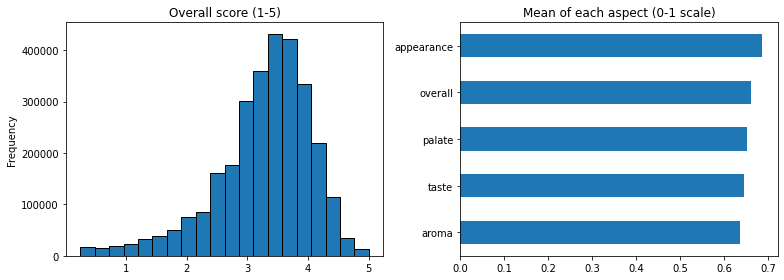

In [36]:
# ============================ 2. Distribution of the overall score ============================
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["score"].plot.hist(bins=20, ax=ax[0], edgecolor="k"); ax[0].set_title("Overall score (1-5)")
df[aspects].mean().sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Mean of each aspect (0-1 scale)")
plt.tight_layout(); plt.show()

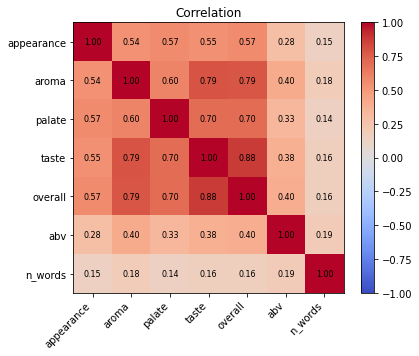

overall       1.000000
taste         0.876243
aroma         0.789023
palate        0.700894
appearance    0.566359
abv           0.397041
n_words       0.161900
Name: overall, dtype: float64


In [37]:
# ============================ 3. Which aspect drives the overall score? ============================
corr = df[aspects + ["abv", "n_words"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Correlation"); plt.tight_layout(); plt.show()
print(corr["overall"].sort_values(ascending=False))

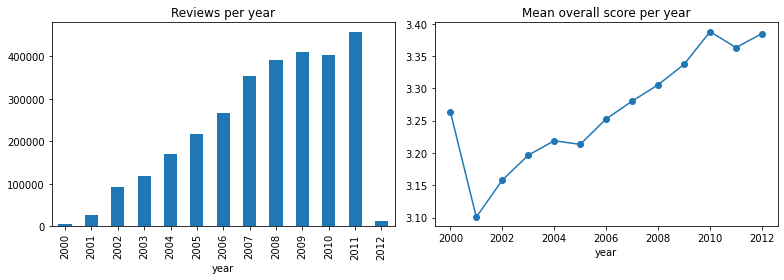

In [38]:
# ============================ 4. Activity and average score over time ============================
by_year = df.groupby("year", observed=True)["score"].agg(["count", "mean"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_year["count"].plot.bar(ax=ax[0]); ax[0].set_title("Reviews per year")
by_year[by_year["count"] >= 100]["mean"].plot(marker="o", ax=ax[1]); ax[1].set_title("Mean overall score per year")
plt.tight_layout(); plt.show()

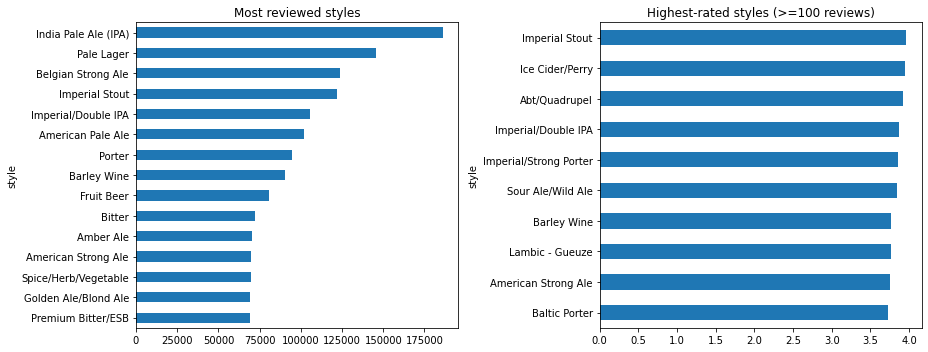

In [39]:
# ============================ 5. Styles: popularity vs. score ============================
st = df.groupby("style", observed=True)["score"].agg(["count", "mean"])
st = st[st["count"] >= 100]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
st["count"].nlargest(15).sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Most reviewed styles")
st["mean"].nlargest(10).sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Highest-rated styles (>=100 reviews)")
plt.tight_layout(); plt.show()

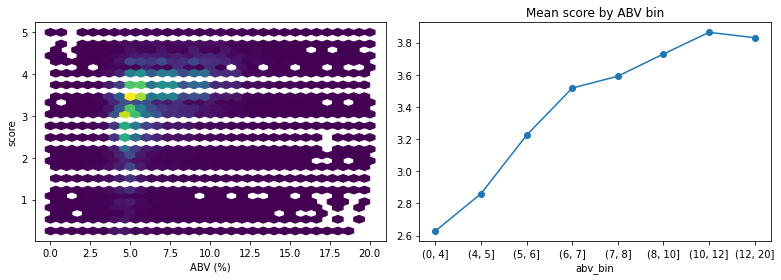

corr(ABV, score) = 0.40224431994711796


In [40]:
# ============================ 6. Does stronger beer score higher? ============================
d = df.dropna(subset=["abv", "score"]); d = d[d["abv"] <= 20].copy()
d["abv_bin"] = pd.cut(d["abv"], [0, 4, 5, 6, 7, 8, 10, 12, 20])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hexbin(d["abv"], d["score"], gridsize=30, cmap="viridis", mincnt=1); ax[0].set_xlabel("ABV (%)"); ax[0].set_ylabel("score")
d.groupby("abv_bin", observed=True)["score"].mean().plot(marker="o", ax=ax[1]); ax[1].set_title("Mean score by ABV bin")
plt.tight_layout(); plt.show()
print("corr(ABV, score) =", d["abv"].corr(d["score"]))
del d

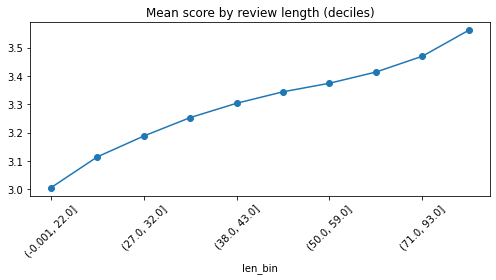

In [41]:
# ============================ 7. Longer reviews = harsher or happier? ============================
d = df.dropna(subset=["score"]).copy()
d["len_bin"] = pd.qcut(d["n_words"], 10, duplicates="drop")
d.groupby("len_bin", observed=True)["score"].mean().plot(marker="o", figsize=(7, 4), title="Mean score by review length (deciles)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
del d

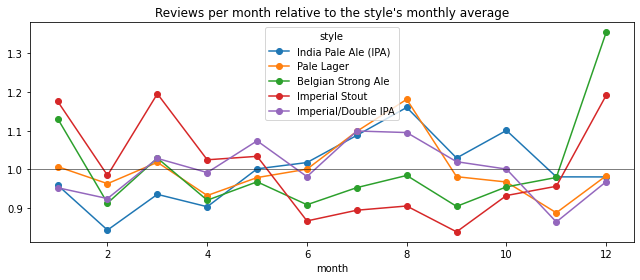

In [42]:
# ============================ 8. Seasonality: which styles are drunk when? ============================
top = df["style"].value_counts().index[:5]
share = pd.crosstab(df["month"], df["style"])[top]
(share / share.mean()).plot(marker="o", figsize=(9, 4), title="Reviews per month relative to the style's monthly average")
plt.axhline(1, color="k", lw=.5); plt.tight_layout(); plt.show()

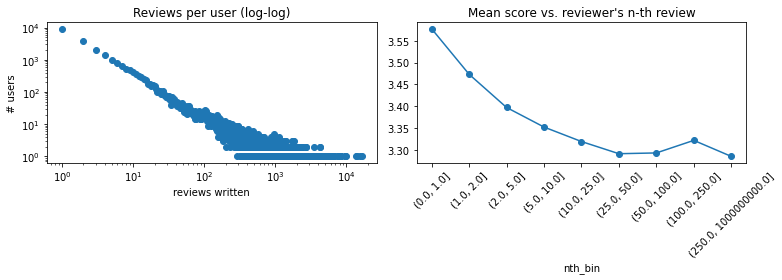

In [43]:
# ============================ 9. Reviewers: long tail and experience effect ============================
u = df.dropna(subset=["user"]).sort_values("date").copy()
vc = u["user"].value_counts().value_counts().sort_index()
u["nth"] = u.groupby("user", observed=True).cumcount() + 1       # n-th review of this user
u["nth_bin"] = pd.cut(u["nth"], [0, 1, 2, 5, 10, 25, 50, 100, 250, 1e9])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(vc.index, vc.values, "o"); ax[0].set_xlabel("reviews written"); ax[0].set_ylabel("# users"); ax[0].set_title("Reviews per user (log-log)")
u.groupby("nth_bin", observed=True)["score"].mean().plot(marker="o", ax=ax[1]); ax[1].set_title("Mean score vs. reviewer's n-th review")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
del u

In [44]:
# ============================ 10. Best, worst and most polarising beers ============================
b = df.groupby("beer_id", observed=True)["score"].agg(["count", "mean", "std"])
b = b[b["count"] >= 100]                      # lower this threshold for a smaller dataset
b["name"] = b.index.map(names)
print("Top rated:\n", b.nlargest(10, "mean"))
print("Lowest rated:\n", b.nsmallest(10, "mean"))
print("Most polarising:\n", b.nlargest(10, "std"))

Top rated:
          count      mean       std  \
beer_id                              
4934      2060  4.556553  0.425360   
58590      262  4.465649  0.472179   
71826      208  4.427885  0.322605   
116684     223  4.427130  0.338108   
80665      102  4.419117  0.326551   
19633      189  4.410053  0.419574   
43181      528  4.405303  0.418138   
28173      483  4.404762  0.451471   
119353     122  4.379098  0.474814   
14232     1606  4.378425  0.414364   

                                                      name  
beer_id                                                     
4934                                       Westvleteren 12  
58590    Three Floyds Oak Aged Dark Lord Russian Imperi...  
71826    Bells Bourbon Barrel Double Cream/Expedition S...  
116684              Goose Island Rare Bourbon County Stout  
80665                                Lost Abbey Yellow Bus  
19633                   De Dolle Stille Nacht Reserva 2000  
43181                      Russian River Pl

In [45]:
# ============================ 11. Which words go with high / low scores? ============================
sums, cnts = defaultdict(float), Counter()
for rec in text_sample:
    s = frac(rec.get("review/overall")) * 5
    if s != s:                                # skip NaN scores
        continue
    for w in set(re.findall(r"[a-z']+", (rec.get("review/text") or "").lower())):
        sums[w] += s; cnts[w] += 1
w = pd.DataFrame({"n": cnts, "sum": pd.Series(sums)})
w["mean"] = w["sum"] / w["n"]
w = w[w["n"] >= 200]                          # ignore rare words
w["diff"] = w["mean"] - df["score"].mean()    # how far the words' reviews are from the average
print("Words of the best reviews:\n", w.nlargest(15, "diff")[["n", "diff"]])
print("Words of the worst reviews:\n", w.nsmallest(15, "diff")[["n", "diff"]])
 

Words of the best reviews:
                 n      diff
incredible    547  0.884720
wonderfully   512  0.795779
superb        494  0.781554
awesome      1763  0.770411
wonderful    2440  0.764011
amazing      1764  0.762293
fantastic    1536  0.744347
beautifully   380  0.741524
rocks         219  0.725190
delicious    2627  0.721774
perfect      2405  0.718164
layers        213  0.712987
terrific      241  0.678292
motor         274  0.675441
amazingly     342  0.669375
Words of the worst reviews:
              n      diff
drain      335 -1.707386
worst      716 -1.608932
awful      562 -1.579283
nasty      542 -1.485348
horrible   585 -1.480693
piss       455 -1.442781
urine      227 -1.423272
swill      345 -1.390503
gross      208 -1.382856
crap       535 -1.370484
sucks      204 -1.361198
miller     434 -1.331030
avoid      217 -1.328726
worse      686 -1.236148
budweiser  271 -1.233503
